# Taller Aplicado 1 — Series de tiempo: métodos estadísticos clásicos vs. redes neuronales NAR y NARX
**Maestría · Inteligencia Computacional · Universidad Distrital Francisco José de Caldas**

Taller guiado y completamente resuelto. Se modela una serie diaria de **demanda** $y_t$ que depende de forma **no lineal** de una variable exógena (**temperatura** $x_t$), con tendencia, estacionalidad semanal y ruido autocorrelacionado. Se comparan:

| Familia | Modelo | Ecuación de predicción |
|---|---|---|
| Referencia | Ingenuo estacional | $\hat y_{t}=y_{t-s}$ |
| Clásico | Holt-Winters aditivo (ETS A,A,A) | $\hat y_{t+h\mid t}=\ell_t+h\,b_t+s_{t+h-m(k+1)}$ |
| Clásico | SARIMAX$(p,d,q)(P,D,Q)_s$ | $\phi(B)\Phi(B^s)\nabla^d\nabla_s^D y_t=c+\boldsymbol\beta^\top\mathbf x_t+\theta(B)\Theta(B^s)\varepsilon_t$ |
| Neuronal | NAR | $\hat y_t=f_{\mathbf W}(y_{t-1},\dots,y_{t-d_y})$ |
| Neuronal | NARX | $\hat y_t=f_{\mathbf W}(y_{t-1},\dots,y_{t-d_y},\,x_t,\dots,x_{t-d_x})$ |



## 0. Parámetros modificables
Todo experimento del subgrupo se hace aquí. Cada parámetro indica qué fenómeno teórico permite estudiar.

In [1]:
# =====================================================================
#            PARÁMETROS MODIFICABLES  (único bloque a editar)
# =====================================================================
SEMILLA          = 43       # Reproducibilidad: fija numpy, python y TensorFlow.

# ---- Datos sintéticos ------------------------------------------------
N_DIAS           = 1095     # Longitud de la serie (3 años diarios).
S                = 7        # Periodo estacional (semana). Usado por todos los modelos.
SIGMA_RUIDO      = 3.0      # Desv. estándar del ruido AR(1): más ruido -> menor predictibilidad.
PHI_RUIDO        = 0.6      # Autocorrelación del ruido: memoria lineal de corto plazo.
NO_LINEALIDAD    = 0.35     # Peso del término cuadrático en temperatura (0 = relación lineal).

# ---- Partición temporal (sin barajar) --------------------------------
PROP_TRAIN       = 0.70     # Entrenamiento.
PROP_VAL         = 0.15     # Validación (parada temprana / selección). Prueba = resto.

# ---- Modelos clásicos ------------------------------------------------
ORDEN_ARIMA      = (2, 0, 1)        # (p, d, q)
ORDEN_ESTACIONAL = (1, 1, 1, S)     # (P, D, Q, s)
EXOG_CUADRATICA  = True     # True: SARIMAX recibe x y x^2 (ingeniería de variables).
BUSCAR_ORDEN     = False    # True: rejilla pequeña de órdenes por AIC (tarda ~1-2 min).

# ---- Redes NAR / NARX ------------------------------------------------
DY               = 14       # Retardos de la salida y (ventana autorregresiva).
DX               = 2        # Retardos de la exógena: usa x_t, x_{t-1}, ..., x_{t-DX}.
NEURONAS         = [12]     # Neuronas por capa oculta. Ej: [12] (una capa) o [16, 8].
ACTIVACION       = "tanh"   # 'tanh' (clásica en NARX), 'relu', 'sigmoid'.
TASA_APRENDIZAJE = 1e-3     # Paso de Adam.
L2               = 1e-4     # Regularización de pesos (penaliza ||W||^2).
EPOCAS           = 600      # Máximo de épocas.
TAM_LOTE         = 32       # Tamaño de mini-lote.
PACIENCIA        = 40       # Parada temprana: épocas sin mejora en validación.
N_REINICIOS      = 3        # Reentrenamientos con distinta inicialización; se queda el mejor en validación.
QUITAR_TENDENCIA = True     # Quita tendencia lineal ajustada SOLO con train antes de la red.

# ---- Evaluación ------------------------------------------------------
HORIZONTE        = 14       # Pasos de pronóstico en lazo cerrado (multipaso).
PASO_ORIGEN      = 7        # Separación entre orígenes de pronóstico en prueba.

## 1. Librerías y reproducibilidad
TensorFlow ya viene en Colab. El taller corre en **CPU** en 2–4 minutos; la GPU no aporta porque las redes son pequeñas (cientos de pesos) y el costo lo domina la sobrecarga de lanzar cada mini-lote.

In [2]:
import os, random, time, itertools, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"          # Silencia mensajes informativos de TF.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
import tensorflow as tf
warnings.filterwarnings("ignore")                 # statsmodels avisa de convergencia en la rejilla.

def fijar_semillas(s):
    # Fijar las tres fuentes de azar hace que pesos iniciales y mini-lotes se repitan.
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
fijar_semillas(SEMILLA)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})
print("TensorFlow", tf.__version__, "| GPU disponible:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPU disponible: False


## 2. Generación del conjunto de datos (proceso generador conocido)
Conocer el proceso verdadero permite saber **qué debería aprender** cada modelo:

$$x_t = 18 + 6\sin\!\Big(\tfrac{2\pi(t-80)}{365.25}\Big) + \eta_t,\qquad \eta_t = 0.7\,\eta_{t-1}+\nu_t,\ \nu_t\sim\mathcal N(0,1.5^2)$$

$$y_t = 200 + 0.03\,t + 10\sin\!\Big(\tfrac{2\pi t}{7}\Big) + 5\cos\!\Big(\tfrac{4\pi t}{7}\Big) + \kappa\,(x_t-18)^2 + 3\tanh(x_{t-1}-20) + u_t$$

$$u_t=\phi\,u_{t-1}+\varepsilon_t,\qquad \varepsilon_t\sim\mathcal N(0,\sigma^2)$$

- La parábola $\kappa(x_t-18)^2$ imita la demanda energética: sube con frío (calefacción) y con calor (refrigeración). **Un modelo lineal en $x_t$ no puede representarla.**
- $\tanh(x_{t-1}-20)$ es un efecto retardado y saturante: motiva incluir retardos de $x$.
- $u_t$ AR(1) da memoria lineal de corto plazo: motiva la parte autorregresiva.

Train: 2023-01-01 a 2025-02-04 (766 días)
Val  : 2025-02-05 a 2025-07-18 (164 días)
Test : 2025-07-19 a 2025-12-30 (165 días)


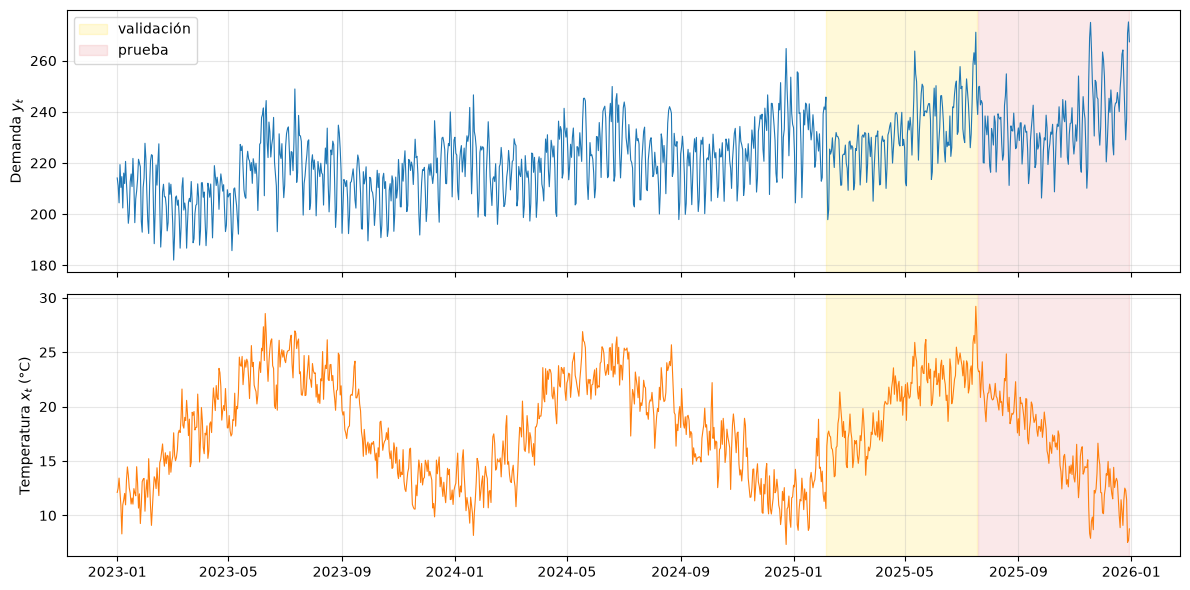

In [3]:
rng = np.random.default_rng(SEMILLA)
t = np.arange(N_DIAS)

# Exógena: ciclo anual + ruido AR(1). Se simula con recursión explícita.
eta = np.zeros(N_DIAS)
for k in range(1, N_DIAS):
    eta[k] = 0.7 * eta[k-1] + rng.normal(0, 1.5)
x = 18 + 6*np.sin(2*np.pi*(t-80)/365.25) + eta

# Ruido de la salida: AR(1) con parámetros modificables.
u = np.zeros(N_DIAS)
for k in range(1, N_DIAS):
    u[k] = PHI_RUIDO * u[k-1] + rng.normal(0, SIGMA_RUIDO)

x_lag1 = np.r_[x[0], x[:-1]]                       # x_{t-1}; en t=0 se repite x_0.
y = (200 + 0.03*t                                  # nivel + tendencia lineal
     + 10*np.sin(2*np.pi*t/7) + 5*np.cos(4*np.pi*t/7)   # estacionalidad semanal (2 armónicos)
     + NO_LINEALIDAD*(x - 18)**2                   # efecto no lineal contemporáneo
     + 3*np.tanh(x_lag1 - 20)                      # efecto retardado saturante
     + u)

fechas = pd.date_range("2023-01-01", periods=N_DIAS, freq="D")
df = pd.DataFrame({"y": y, "x": x}, index=fechas)

# Partición temporal: los índices crecen con el tiempo; nunca se baraja.
n_tr = int(PROP_TRAIN * N_DIAS)
n_va = int(PROP_VAL * N_DIAS)
i_va, i_te = n_tr, n_tr + n_va                     # inicio de validación y de prueba
print(f"Train: {fechas[0].date()} a {fechas[i_va-1].date()} ({n_tr} días)")
print(f"Val  : {fechas[i_va].date()} a {fechas[i_te-1].date()} ({n_va} días)")
print(f"Test : {fechas[i_te].date()} a {fechas[-1].date()} ({N_DIAS-i_te} días)")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(df.y, lw=.8); ax[0].set_ylabel("Demanda $y_t$")
ax[1].plot(df.x, lw=.8, color="tab:orange"); ax[1].set_ylabel("Temperatura $x_t$ (°C)")
for a in ax:
    a.axvspan(fechas[i_va], fechas[i_te-1], color="gold", alpha=.15, label="validación")
    a.axvspan(fechas[i_te], fechas[-1], color="tab:red", alpha=.10, label="prueba")
ax[0].legend(loc="upper left"); plt.tight_layout(); plt.show()

## 3. Análisis exploratorio con rigor estadístico (solo sobre *train*)
Todo diagnóstico se calcula con el conjunto de entrenamiento: usar validación o prueba para decidir el modelo sería **fuga de información**.

**Pruebas de raíz unitaria.** ADF: $H_0$ = hay raíz unitaria (no estacionaria). KPSS: $H_0$ = estacionaria. Se usan juntas porque tienen hipótesis nulas opuestas:

| ADF rechaza | KPSS rechaza | Conclusión |
|---|---|---|
| Sí | No | Estacionaria |
| No | Sí | Raíz unitaria: diferenciar |
| Sí | Sí | Estacionaria en tendencia / diferencia fraccional |
| No | No | Datos insuficientes |

y_t (nivel)                      ADF p=0.5721 | KPSS p=0.0100
Diferencia estacional (1-B^7) y_t ADF p=0.0000 | KPSS p=0.1000
(1-B)(1-B^7) y_t                 ADF p=0.0000 | KPSS p=0.1000


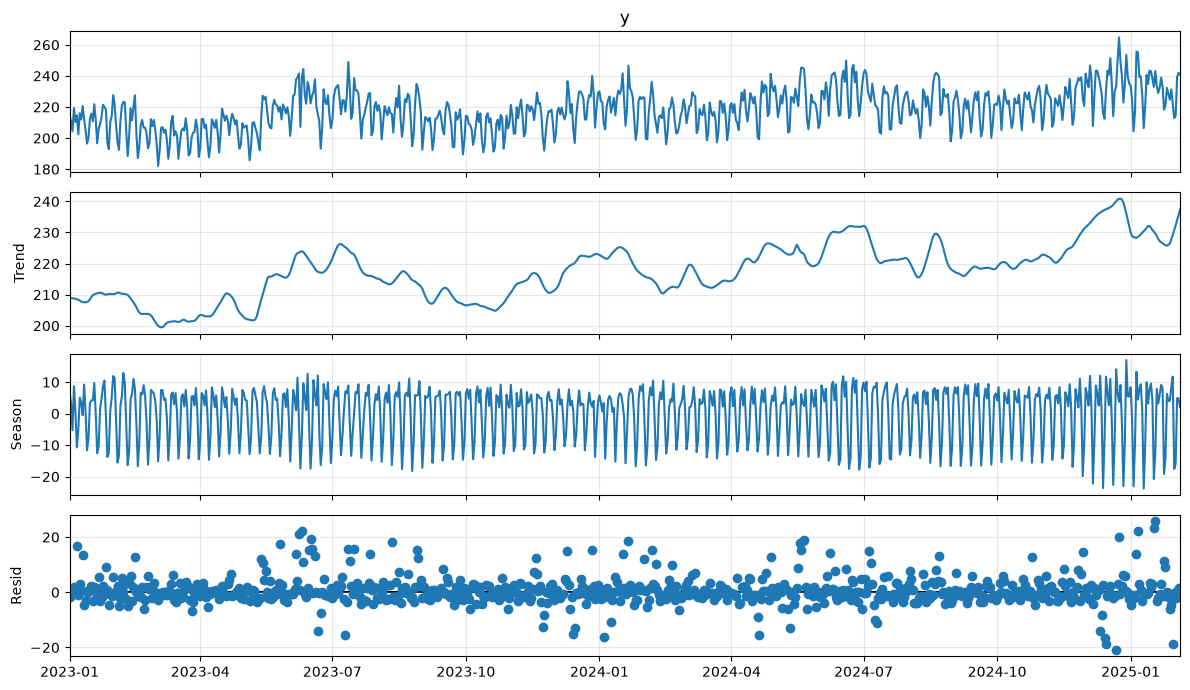

Fuerza de tendencia F_T = 0.756 | Fuerza estacional F_S = 0.703


In [4]:
y_tr = df.y.iloc[:n_tr]

def pruebas_estacionariedad(serie, nombre):
    adf_p  = adfuller(serie, autolag="AIC")[1]                    # p-valor ADF
    kpss_p = kpss(serie, regression="c", nlags="auto")[1]         # p-valor KPSS (acotado 0.01-0.10)
    print(f"{nombre:<32s} ADF p={adf_p:6.4f} | KPSS p={kpss_p:6.4f}")

pruebas_estacionariedad(y_tr, "y_t (nivel)")
pruebas_estacionariedad(y_tr.diff(S).dropna(), f"Diferencia estacional (1-B^{S}) y_t")
pruebas_estacionariedad(y_tr.diff().diff(S).dropna(), f"(1-B)(1-B^{S}) y_t")

# Descomposición STL: separa tendencia T_t, estacionalidad S_t y resto R_t con LOESS robusto.
stl = STL(y_tr, period=S, robust=True).fit()
stl.plot(); plt.gcf().set_size_inches(12, 7); plt.tight_layout(); plt.show()

# Fuerza de la estacionalidad (Wang, Smith & Hyndman, 2006): F_S = max(0, 1 - Var(R)/Var(S+R)).
F_S = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
F_T = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
print(f"Fuerza de tendencia F_T = {F_T:.3f} | Fuerza estacional F_S = {F_S:.3f}")

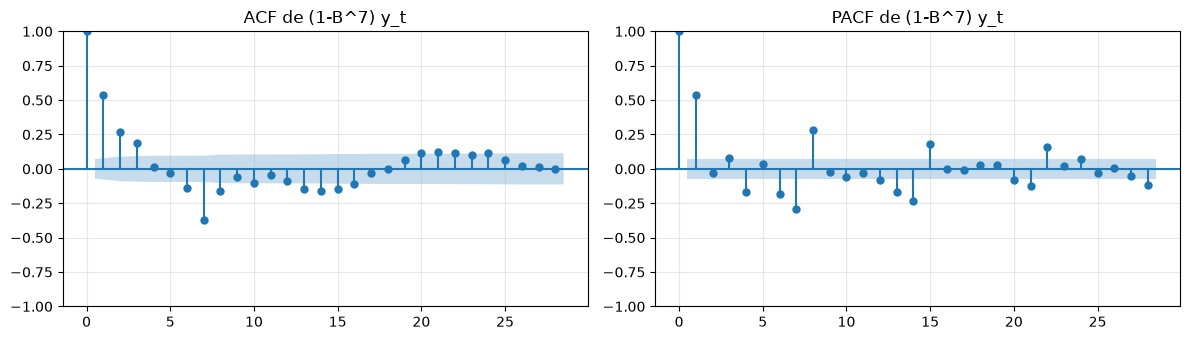

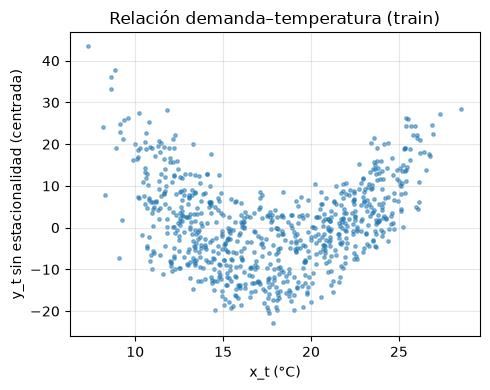

In [5]:
# ACF/PACF de la serie diferenciada estacionalmente: guía para elegir (p,q)(P,Q).
# Picos de PACF en 1..p sugieren AR(p); picos de ACF en múltiplos de S sugieren términos estacionales.
z = y_tr.diff(S).dropna()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(z, lags=4*S, ax=ax[0]);  ax[0].set_title(f"ACF de (1-B^{S}) y_t")
plot_pacf(z, lags=4*S, ax=ax[1], method="ywm"); ax[1].set_title(f"PACF de (1-B^{S}) y_t")
plt.tight_layout(); plt.show()

# Dispersión y vs x: la curvatura evidencia la relación no lineal que un SARIMAX lineal no captura.
plt.figure(figsize=(5, 4))
plt.scatter(df.x.iloc[:n_tr], stl.resid + stl.trend - stl.trend.mean(), s=6, alpha=.5)
plt.xlabel("x_t (°C)"); plt.ylabel("y_t sin estacionalidad (centrada)")
plt.title("Relación demanda–temperatura (train)"); plt.tight_layout(); plt.show()

## 4. Métricas de desempeño
Para errores $e_t=y_t-\hat y_t$ en $T$ puntos de prueba:

$$\text{RMSE}=\sqrt{\tfrac1T\sum e_t^2},\quad \text{MAE}=\tfrac1T\sum|e_t|,\quad \text{MAPE}=\tfrac{100}{T}\sum\Big|\tfrac{e_t}{y_t}\Big|,\quad \text{sMAPE}=\tfrac{200}{T}\sum\tfrac{|e_t|}{|y_t|+|\hat y_t|}$$

$$\text{MASE}=\frac{\text{MAE}}{\tfrac{1}{n-s}\sum_{t=s+1}^{n}|y_t-y_{t-s}|}\quad(\text{escala del ingenuo estacional en } train)$$

MASE < 1 significa que el modelo supera al ingenuo estacional; es comparable entre series (Hyndman & Koehler, 2006). MAPE se reporta, pero es inestable si $y_t\to0$.

In [6]:
ESCALA_MASE = np.mean(np.abs(y_tr.values[S:] - y_tr.values[:-S]))   # MAE del ingenuo estacional en train

def metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    e = y_real - y_pred
    return {"RMSE": np.sqrt(np.mean(e**2)),
            "MAE": np.mean(np.abs(e)),
            "MAPE(%)": 100*np.mean(np.abs(e / y_real)),
            "sMAPE(%)": 200*np.mean(np.abs(e) / (np.abs(y_real) + np.abs(y_pred))),
            "MASE": np.mean(np.abs(e)) / ESCALA_MASE}
print(f"Escala MASE (MAE ingenuo estacional en train) = {ESCALA_MASE:.3f}")

Escala MASE (MAE ingenuo estacional en train) = 7.050


## 5. Modelos estadísticos clásicos
### 5.1 Holt-Winters aditivo
$$\ell_t=\alpha(y_t-s_{t-m})+(1-\alpha)(\ell_{t-1}+b_{t-1}),\quad b_t=\beta^*(\ell_t-\ell_{t-1})+(1-\beta^*)b_{t-1},\quad s_t=\gamma(y_t-\ell_{t-1}-b_{t-1})+(1-\gamma)s_{t-m}$$
Los parámetros $(\alpha,\beta^*,\gamma)$ y los estados iniciales se estiman en *train* por máxima verosimilitud y luego **se congelan**: en prueba solo se actualizan los estados con los datos nuevos (igual que en producción).

In [7]:
hw_fit = ExponentialSmoothing(y_tr, trend="add", seasonal="add", seasonal_periods=S,
                              initialization_method="estimated").fit()
P_HW = dict(smoothing_level=hw_fit.params["smoothing_level"],
            smoothing_trend=hw_fit.params["smoothing_trend"],
            smoothing_seasonal=hw_fit.params["smoothing_seasonal"])
INIT_HW = dict(initial_level=hw_fit.params["initial_level"],
               initial_trend=hw_fit.params["initial_trend"],
               initial_seasonal=hw_fit.params["initial_seasons"])
print({k: round(v, 4) for k, v in P_HW.items()})

def hw_filtrar(serie):
    # Re-filtra la serie con parámetros y estados iniciales FIJOS (sin re-estimar con datos futuros).
    m = ExponentialSmoothing(serie, trend="add", seasonal="add", seasonal_periods=S,
                             initialization_method="known", **INIT_HW)
    return m.fit(optimized=False, **P_HW)

{'smoothing_level': np.float64(0.6331), 'smoothing_trend': np.float64(0.0), 'smoothing_seasonal': np.float64(0.0)}


### 5.2 SARIMAX
Con el operador de retardo $B y_t=y_{t-1}$:
$$\underbrace{\phi_p(B)}_{\text{AR}}\ \underbrace{\Phi_P(B^s)}_{\text{AR estacional}}\ (1-B)^d(1-B^s)^D\,y_t \;=\; c+\boldsymbol\beta^\top\mathbf x_t+\underbrace{\theta_q(B)}_{\text{MA}}\ \underbrace{\Theta_Q(B^s)}_{\text{MA estacional}}\,\varepsilon_t$$
La estimación es por máxima verosimilitud exacta con el filtro de Kalman (representación en espacio de estados). Por defecto la exógena entra **linealmente**; con `EXOG_CUADRATICA=True` se añade $x_t^2$ y se evalúa cuánto aporta la ingeniería de variables frente a la no linealidad aprendida por NARX.

In [8]:
def exogenas(xs):
    X = pd.DataFrame({"x": xs}, index=df.index[:len(xs)])
    if EXOG_CUADRATICA:
        X["x2"] = (xs - 18)**2          # término cuadrático centrado (evita colinealidad con x)
    return X
X_all = exogenas(df.x.values)

if BUSCAR_ORDEN:
    # Rejilla pequeña por AIC = -2 logL + 2k. Solo con train.
    mejor = (np.inf, None)
    for p, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
        try:
            r = SARIMAX(y_tr, exog=X_all.iloc[:n_tr], order=(p, 0, q), seasonal_order=(P, 1, Q, S),
                        trend="c").fit(disp=False)
            if r.aic < mejor[0]:
                mejor = (r.aic, ((p, 0, q), (P, 1, Q, S)))
        except Exception:
            pass
    ORDEN_ARIMA, ORDEN_ESTACIONAL = mejor[1]
    print("Orden elegido por AIC:", mejor[1], "AIC =", round(mejor[0], 1))

t0 = time.time()
sar_fit = SARIMAX(y_tr, exog=X_all.iloc[:n_tr], order=ORDEN_ARIMA, seasonal_order=ORDEN_ESTACIONAL,
                  trend="c").fit(disp=False)
T_SARIMAX = time.time() - t0
print(sar_fit.summary().tables[1])
print(f"AIC={sar_fit.aic:.1f}  BIC={sar_fit.bic:.1f}  tiempo={T_SARIMAX:.1f}s")

# Diagnóstico de residuos: Ljung-Box  Q = n(n+2) sum_k r_k^2/(n-k) ~ chi^2.
# p-valor alto => residuos compatibles con ruido blanco (el modelo extrajo la estructura lineal).
lb = acorr_ljungbox(sar_fit.resid[S+1:], lags=[S, 2*S, 3*S])
print("Ljung-Box residuos SARIMAX:\n", lb.round(4))

# Se "aplican" los parámetros fijos a TODA la serie: así las predicciones en prueba
# usan solo información disponible hasta cada origen, sin re-estimar con datos de prueba.
sar_all = sar_fit.apply(df.y, exog=X_all)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.1311      0.048      2.712      0.007       0.036       0.226
x              0.2416      0.052      4.690      0.000       0.141       0.343
x2             0.3466      0.008     41.582      0.000       0.330       0.363
ar.L1         -0.0246      0.595     -0.041      0.967      -1.191       1.142
ar.L2          0.3179      0.352      0.902      0.367      -0.373       1.008
ma.L1          0.6150      0.585      1.051      0.293      -0.532       1.762
ar.S.L7        0.0852      0.041      2.082      0.037       0.005       0.165
ma.S.L7       -0.9999      2.284     -0.438      0.662      -5.476       3.476
sigma2         9.7307     22.109      0.440      0.660     -33.602      53.063
AIC=3930.9  BIC=3972.6  tiempo=2.4s
Ljung-Box residuos SARIMAX:
     lb_stat  lb_pvalue
7    4.9087     0.6711
14  14.9969     0.37

## 6. Redes neuronales NAR y NARX
### 6.1 Formulación
Vector de regresores (*tapped delay line*):
$$\mathbf z_t=\big[y_{t-1},\dots,y_{t-d_y}\,\big|\,x_t,x_{t-1},\dots,x_{t-d_x}\big]^\top\in\mathbb R^{d_y+d_x+1}$$
Perceptrón multicapa con una capa oculta de $H$ neuronas:
$$\hat y_t=f_{\mathbf W}(\mathbf z_t)=\mathbf w_2^\top\,\sigma\!\big(\mathbf W_1\mathbf z_t+\mathbf b_1\big)+b_2$$
Pérdida con regularización L2: $\ \mathcal L(\mathbf W)=\tfrac1N\sum_t\big(y_t-\hat y_t\big)^2+\lambda\lVert\mathbf W\rVert_2^2$.

**Lazo abierto (serie-paralelo)**: en entrenamiento los retardos de $y$ son **valores reales** (*teacher forcing*). Es un problema de regresión estático, rápido y estable.
**Lazo cerrado (paralelo)**: para pronosticar $h$ pasos, los retardos se reemplazan por **predicciones previas**: $\hat y_{t+h}=f(\hat y_{t+h-1},\dots)$; el error se realimenta y se acumula. NAR es el caso $d_x=-1$ (sin exógena).

In [9]:
# --- Preprocesamiento sin fuga: tendencia y escalado se ajustan SOLO con train ---
if QUITAR_TENDENCIA:
    coef_tend = np.polyfit(t[:n_tr], y[:n_tr], 1)     # OLS de y sobre t usando solo train
    tend = np.polyval(coef_tend, t)                    # se extrapola a val/test (conocida a priori)
else:
    tend = np.zeros(N_DIAS)
y_dt = y - tend
mu_y, sd_y = y_dt[:n_tr].mean(), y_dt[:n_tr].std()    # z-score: tanh trabaja bien con entradas ~N(0,1)
mu_x, sd_x = x[:n_tr].mean(), x[:n_tr].std()
ys, xs = (y_dt - mu_y)/sd_y, (x - mu_x)/sd_x
desescalar = lambda v, idx: v*sd_y + mu_y + tend[idx]  # vuelve a unidades originales

L0 = max(DY, DX)                                       # primer índice con historia completa

def regresores(yv, xv, idx, con_x):
    # Fila por instante t: [y_{t-1..t-DY}, x_{t..t-DX}]. Solo usa el pasado de y (sin fuga).
    Z = [yv[idx - k] for k in range(1, DY + 1)]
    if con_x:
        Z += [xv[idx - k] for k in range(0, DX + 1)]
    return np.column_stack(Z)

idx_tr = np.arange(L0, n_tr)
idx_va = np.arange(n_tr, i_te)
idx_te = np.arange(i_te, N_DIAS)

NAR  reinicio 1: val_loss=0.3028  épocas=198  tiempo=29.1s


NAR  reinicio 2: val_loss=0.2832  épocas=217  tiempo=25.2s


NAR  reinicio 3: val_loss=0.3064  épocas=138  tiempo=16.8s
NAR : parámetros entrenables = 193


NARX reinicio 1: val_loss=0.1391  épocas=450  tiempo=52.2s


NARX reinicio 2: val_loss=0.1491  épocas=352  tiempo=41.4s


NARX reinicio 3: val_loss=0.1506  épocas=600  tiempo=70.7s
NARX: parámetros entrenables = 229


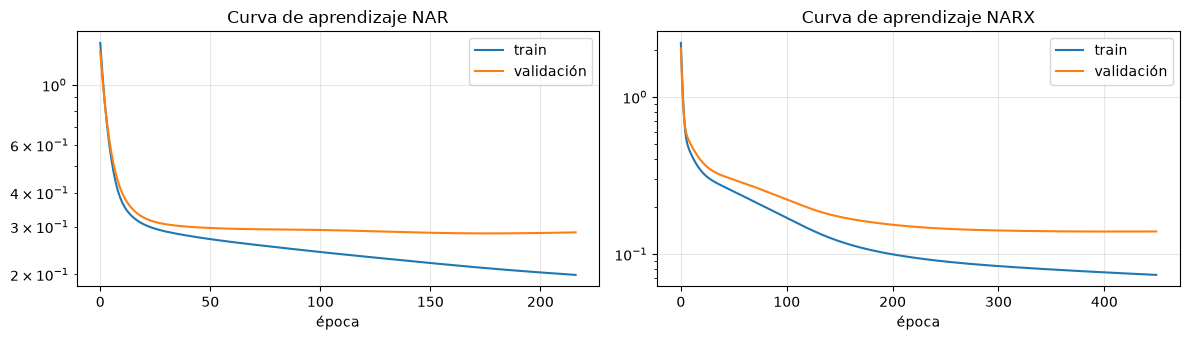

In [10]:
def construir_red(n_ent):
    reg = tf.keras.regularizers.l2(L2)
    capas = [tf.keras.Input(shape=(n_ent,))]
    for h in NEURONAS:
        capas.append(tf.keras.layers.Dense(h, activation=ACTIVACION, kernel_regularizer=reg))
    capas.append(tf.keras.layers.Dense(1))             # salida lineal: regresión
    red = tf.keras.Sequential(capas)
    red.compile(optimizer=tf.keras.optimizers.Adam(TASA_APRENDIZAJE), loss="mse")
    return red

def entrenar(con_x, nombre):
    Ztr, Zva = regresores(ys, xs, idx_tr, con_x), regresores(ys, xs, idx_va, con_x)
    mejor = None
    for r in range(N_REINICIOS):
        fijar_semillas(SEMILLA + 100*r)                # inicialización distinta en cada reinicio
        red = construir_red(Ztr.shape[1])
        pt = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA,
                                              restore_best_weights=True)
        t0 = time.time()
        h = red.fit(Ztr, ys[idx_tr], validation_data=(Zva, ys[idx_va]), epochs=EPOCAS,
                    batch_size=TAM_LOTE, callbacks=[pt], verbose=0, shuffle=True)
        # shuffle=True es válido: cada fila ya contiene su propio pasado; el orden temporal
        # se preserva en la PARTICIÓN, que es donde importa para evitar fuga.
        vl = min(h.history["val_loss"])
        print(f"{nombre} reinicio {r+1}: val_loss={vl:.4f}  épocas={len(h.history['loss'])}  "
              f"tiempo={time.time()-t0:.1f}s")
        if mejor is None or vl < mejor[0]:
            mejor = (vl, red, h.history, time.time()-t0)
    print(f"{nombre}: parámetros entrenables = {mejor[1].count_params()}")
    return mejor[1], mejor[2], mejor[3]

red_nar,  hist_nar,  T_NAR  = entrenar(False, "NAR ")
red_narx, hist_narx, T_NARX = entrenar(True,  "NARX")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, hst, nm in [(ax[0], hist_nar, "NAR"), (ax[1], hist_narx, "NARX")]:
    a.plot(hst["loss"], label="train"); a.plot(hst["val_loss"], label="validación")
    a.set_yscale("log"); a.set_title(f"Curva de aprendizaje {nm}"); a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

## 7. Evaluación 1: pronóstico a un paso ($h=1$) en prueba
Todos los modelos reciben los valores reales hasta $t-1$ y predicen $y_t$. Es el escenario de lazo abierto.

Métricas en prueba, h = 1


,RMSE,MAE,MAPE(%),sMAPE(%),MASE
Ingenuo estacional,11.267,8.637,3.629,3.629,1.225
Holt-Winters,6.564,4.949,2.076,2.077,0.702
SARIMAX,3.440,2.655,1.140,1.139,0.377
NAR,6.940,5.290,2.224,2.230,0.750
NARX,4.995,3.773,1.602,1.607,0.535


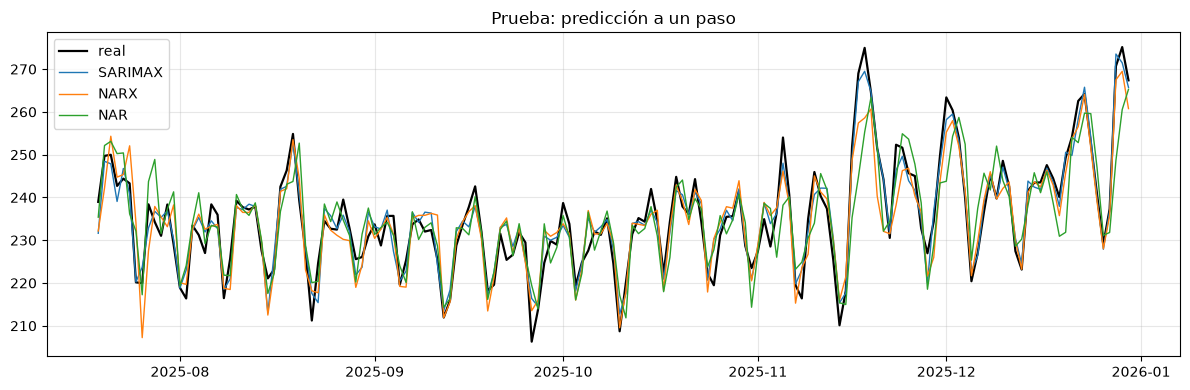

In [11]:
pred1 = {}
pred1["Ingenuo estacional"] = y[idx_te - S]
pred1["Holt-Winters"] = hw_filtrar(df.y).fittedvalues.values[idx_te]       # predicción a 1 paso
pred1["SARIMAX"] = sar_all.get_prediction(start=i_te, end=N_DIAS-1, exog=None).predicted_mean.values
pred1["NAR"]  = desescalar(red_nar.predict(regresores(ys, xs, idx_te, False), verbose=0).ravel(), idx_te)
pred1["NARX"] = desescalar(red_narx.predict(regresores(ys, xs, idx_te, True), verbose=0).ravel(), idx_te)

tabla1 = pd.DataFrame({m: metricas(y[idx_te], p) for m, p in pred1.items()}).T.round(3)
print("Métricas en prueba, h = 1"); display(tabla1)

plt.figure(figsize=(12, 4))
plt.plot(fechas[idx_te], y[idx_te], "k", lw=1.6, label="real")
for m in ["SARIMAX", "NARX", "NAR"]:
    plt.plot(fechas[idx_te], pred1[m], lw=1, label=m)
plt.title("Prueba: predicción a un paso"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Evaluación 2: pronóstico multipaso en lazo cerrado (origen móvil)
Desde cada origen $o$ en prueba se pronostica $\{\hat y_{o},\dots,\hat y_{o+H-1}\}$ sin ver $y$ en ese tramo. Para SARIMAX/NARX se asume **conocida la exógena futura** (escenario de pronóstico condicional; en producción $x$ vendría de un pronóstico meteorológico con su propio error).

Error por horizonte: $\ \text{RMSE}(h)=\sqrt{\tfrac{1}{|\mathcal O|}\sum_{o\in\mathcal O}\big(y_{o+h-1}-\hat y_{o+h-1\mid o-1}\big)^2}$

Métricas en prueba, lazo cerrado, H=14, 22 orígenes


,RMSE,MAE,MAPE(%),sMAPE(%),MASE
Ingenuo estacional,11.420,8.488,3.588,3.579,1.204
Holt-Winters,11.165,8.140,3.445,3.424,1.155
SARIMAX,3.479,2.678,1.156,1.155,0.380
NAR,9.925,7.135,2.997,3.015,1.012
NARX,6.027,4.483,1.917,1.920,0.636


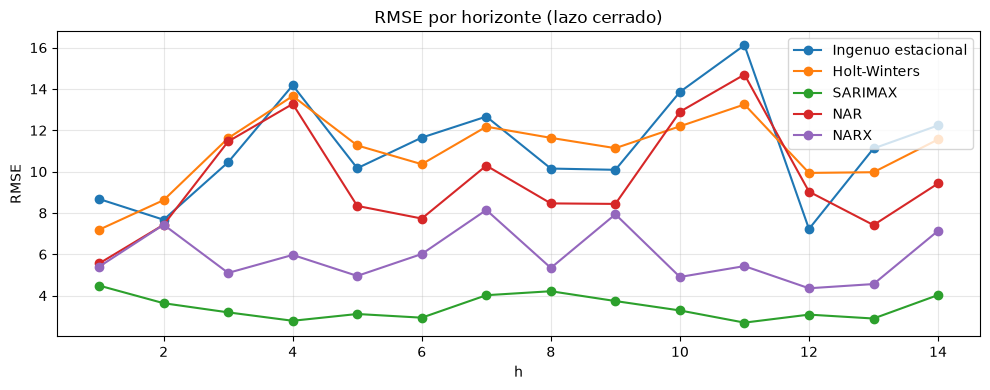

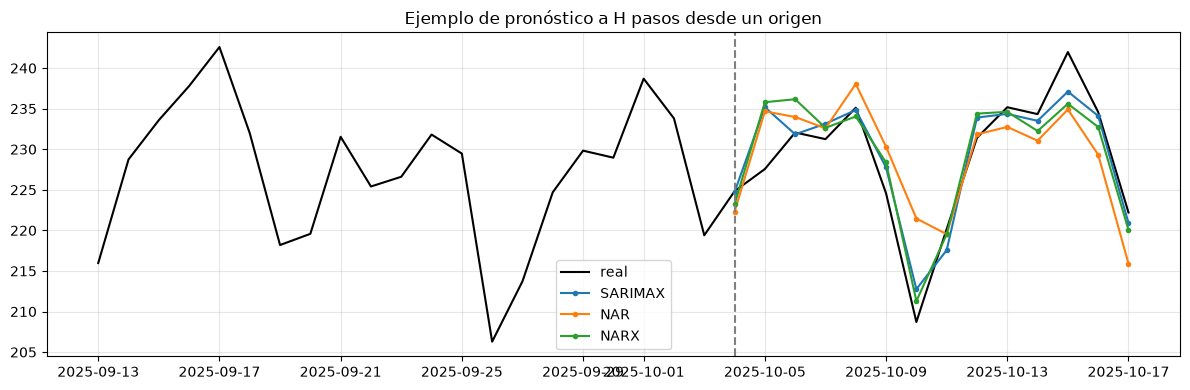

In [12]:
origenes = np.arange(i_te, N_DIAS - HORIZONTE + 1, PASO_ORIGEN)

def lazo_cerrado(red, o, con_x):
    # Recursión: el buffer de y comienza con valores reales y se alimenta con predicciones.
    yb = ys.copy()
    for k in range(o, o + HORIZONTE):
        z = regresores(yb, xs, np.array([k]), con_x)
        yb[k] = red(z, training=False).numpy().ravel()[0]
    idx = np.arange(o, o + HORIZONTE)
    return desescalar(yb[idx], idx)

def ingenuo_multipaso(o):
    ult = y[o - S:o]                                   # última semana observada
    return np.array([ult[h % S] for h in range(HORIZONTE)])

predH = {m: [] for m in pred1}
for o in origenes:
    predH["Ingenuo estacional"].append(ingenuo_multipaso(o))
    predH["Holt-Winters"].append(hw_filtrar(df.y.iloc[:o]).forecast(HORIZONTE).values)
    predH["SARIMAX"].append(sar_all.get_prediction(start=o, end=o+HORIZONTE-1, dynamic=o).predicted_mean.values)
    predH["NAR"].append(lazo_cerrado(red_nar, o, False))
    predH["NARX"].append(lazo_cerrado(red_narx, o, True))
realH = np.array([y[o:o+HORIZONTE] for o in origenes])
predH = {m: np.array(v) for m, v in predH.items()}

rmse_h = pd.DataFrame({m: np.sqrt(np.mean((realH - p)**2, axis=0)) for m, p in predH.items()},
                      index=pd.RangeIndex(1, HORIZONTE+1, name="h"))
tablaH = pd.DataFrame({m: metricas(realH.ravel(), p.ravel()) for m, p in predH.items()}).T.round(3)
print(f"Métricas en prueba, lazo cerrado, H={HORIZONTE}, {len(origenes)} orígenes"); display(tablaH)

rmse_h.plot(marker="o", figsize=(10, 4), title="RMSE por horizonte (lazo cerrado)")
plt.ylabel("RMSE"); plt.tight_layout(); plt.show()

o = origenes[len(origenes)//2]                         # un origen ilustrativo
k = list(origenes).index(o)
plt.figure(figsize=(12, 4))
plt.plot(fechas[o-3*S:o+HORIZONTE], y[o-3*S:o+HORIZONTE], "k", label="real")
for m in ["SARIMAX", "NAR", "NARX"]:
    plt.plot(fechas[o:o+HORIZONTE], predH[m][k], marker=".", label=m)
plt.axvline(fechas[o], ls="--", c="gray"); plt.title("Ejemplo de pronóstico a H pasos desde un origen")
plt.legend(); plt.tight_layout(); plt.show()

## 9. Diagnóstico de residuos y prueba de Diebold-Mariano
Un buen modelo deja residuos sin estructura (ruido blanco). La prueba **Diebold-Mariano** contrasta $H_0$: igual exactitud esperada. Con pérdida cuadrática, $d_t=e_{1,t}^2-e_{2,t}^2$:
$$DM=\frac{\bar d}{\sqrt{\hat\gamma_0/T}}\,,\qquad DM^*=DM\sqrt{\frac{T+1-2h+h(h-1)/T}{T}}\sim t_{T-1}\ \ (\text{corrección de Harvey, Leybourne y Newbold, 1997})$$

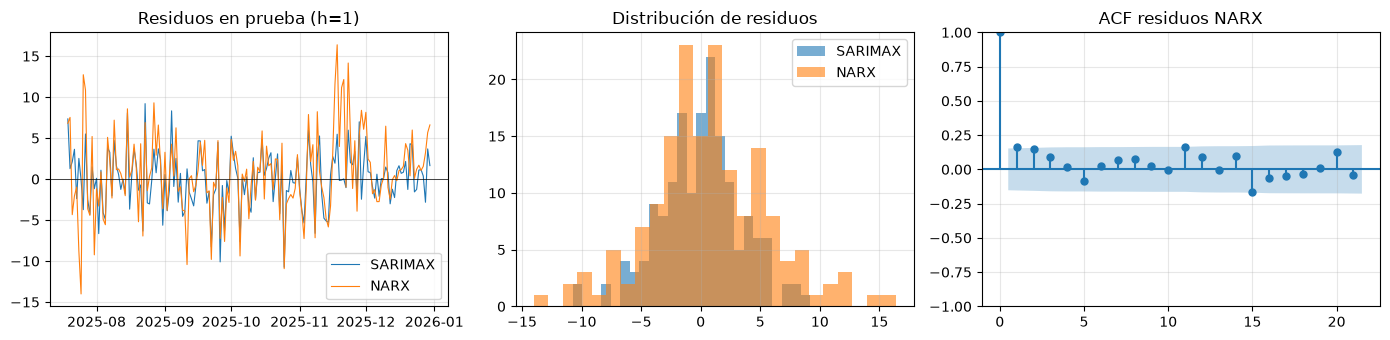

Ljung-Box residuos NARX (prueba):
     lb_stat  lb_pvalue
7   12.1577     0.0955
14  21.4443     0.0908
DM      SARIMAX vs NARX    : DM*= -4.334  p=0.0000  -> diferencia significativa a favor de SARIMAX
DM          NAR vs NARX    : DM*=  3.717  p=0.0003  -> diferencia significativa a favor de NARX
DM Holt-Winters vs SARIMAX : DM*=  5.212  p=0.0000  -> diferencia significativa a favor de SARIMAX


In [13]:
res_narx = y[idx_te] - pred1["NARX"]
res_sar  = y[idx_te] - pred1["SARIMAX"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(fechas[idx_te], res_sar, lw=.8, label="SARIMAX"); ax[0].plot(fechas[idx_te], res_narx, lw=.8, label="NARX")
ax[0].axhline(0, c="k", lw=.5); ax[0].legend(); ax[0].set_title("Residuos en prueba (h=1)")
ax[1].hist(res_sar, bins=25, alpha=.6, label="SARIMAX"); ax[1].hist(res_narx, bins=25, alpha=.6, label="NARX")
ax[1].legend(); ax[1].set_title("Distribución de residuos")
plot_acf(res_narx, lags=3*S, ax=ax[2]); ax[2].set_title("ACF residuos NARX")
plt.tight_layout(); plt.show()
print("Ljung-Box residuos NARX (prueba):\n", acorr_ljungbox(res_narx, lags=[S, 2*S]).round(4))

def diebold_mariano(e1, e2, h=1):
    d = e1**2 - e2**2
    T = len(d)
    gamma = [np.sum((d[k:] - d.mean()) * (d[:T-k] - d.mean())) / T for k in range(h)]
    var_d = (gamma[0] + 2*sum(gamma[1:])) / T
    dm = d.mean() / np.sqrt(var_d)
    dm *= np.sqrt((T + 1 - 2*h + h*(h-1)/T) / T)      # corrección HLN
    p = 2 * stats.t.sf(np.abs(dm), df=T-1)
    return dm, p

for a, b in [("SARIMAX", "NARX"), ("NAR", "NARX"), ("Holt-Winters", "SARIMAX")]:
    dm, p = diebold_mariano(y[idx_te] - pred1[a], y[idx_te] - pred1[b])
    gana = b if dm > 0 else a
    print(f"DM {a:>12s} vs {b:<8s}: DM*={dm:7.3f}  p={p:.4f}  -> "
          f"{'diferencia significativa a favor de ' + gana if p < 0.05 else 'sin diferencia significativa (5%)'}")

## 10. Resumen comparativo y costo computacional

In [14]:
resumen = pd.DataFrame({
    "RMSE h=1": tabla1["RMSE"], "MASE h=1": tabla1["MASE"],
    f"RMSE H={HORIZONTE}": tablaH["RMSE"], f"MASE H={HORIZONTE}": tablaH["MASE"]})
resumen["Tiempo ajuste (s)"] = [0.0, np.nan, T_SARIMAX, T_NAR, T_NARX]
resumen.loc["Holt-Winters", "Tiempo ajuste (s)"] = np.nan
resumen["Parámetros"] = [0, len(P_HW) + 2 + S, len(sar_fit.params), red_nar.count_params(), red_narx.count_params()]
display(resumen.round(3).sort_values(f"RMSE H={HORIZONTE}"))
print("Configuración:", dict(DY=DY, DX=DX, NEURONAS=NEURONAS, ACTIVACION=ACTIVACION, L2=L2,
                            ORDEN=ORDEN_ARIMA, ESTACIONAL=ORDEN_ESTACIONAL, EXOG_CUADRATICA=EXOG_CUADRATICA))

,RMSE h=1,MASE h=1,RMSE H=14,MASE H=14,Tiempo ajuste (s),Parámetros
SARIMAX,3.440,0.377,3.479,0.380,2.434,9
NARX,4.995,0.535,6.027,0.636,52.243,229
NAR,6.940,0.750,9.925,1.012,25.167,193
Holt-Winters,6.564,0.702,11.165,1.155,NaN,12
Ingenuo estacional,11.267,1.225,11.420,1.204,0.000,0


Configuración: {'DY': 14, 'DX': 2, 'NEURONAS': [12], 'ACTIVACION': 'tanh', 'L2': 0.0001, 'ORDEN': (2, 0, 1), 'ESTACIONAL': (1, 1, 1, 7), 'EXOG_CUADRATICA': True}


## 11. Experimentos para los subgrupos (Momento 2)
Cada subgrupo ejecuta **uno** de estos experimentos, registra la tabla del paso 10 y prepara 3 minutos de conclusiones.

| Subgrupo | Cambio en la celda 0 | Pregunta a responder |
|---|---|---|
| 1 | `EXOG_CUADRATICA = True` | ¿La ingeniería de variables cierra la brecha entre SARIMAX y NARX? ¿Qué dice Diebold-Mariano? |
| 2 | `NO_LINEALIDAD = 0.0` | Si el proceso es lineal, ¿la red sigue ganando? ¿Qué modelo elegiría por parsimonia? |
| 3 | `DY` ∈ {3, 7, 14, 28} | ¿Cómo cambia el error a 1 paso vs. multipaso? Relacione con el periodo estacional y la PACF. |
| 4 | `NEURONAS` ∈ {[4], [12], [64], [32,16]} y `L2` ∈ {0, 1e-3} | Sesgo-varianza: ¿cuándo aparece sobreajuste en las curvas de aprendizaje? |
| 5 | `SIGMA_RUIDO` ∈ {1, 3, 6} | ¿La ventaja de la red se mantiene con baja relación señal/ruido? |
| 6 | `QUITAR_TENDENCIA = False` | ¿Por qué una red con `tanh` no extrapola la tendencia? Observe el sesgo en prueba. |
| 7 | `SEMILLA` ∈ {1, 2, 3, 4, 5} | Variabilidad entre inicializaciones: ¿la diferencia NARX–SARIMAX es robusta? |

